In [97]:
import astropy
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from pathlib import Path

# Section 1

In [98]:
# import bias, dark, dark_temp, and illuminated frames

calib_path = Path('P3_calib')
if not calib_path.is_dir():
    calib_path = Path('pset3/P3_calib')

bias_frames = [fits.getdata(path) for path in sorted((calib_path / 'bias').glob('bias_*.fits'))]
dark_frames = [fits.getdata(path) for path in sorted((calib_path / 'dark').glob('dark_*.fits'))]
dark_temp_frames = [fits.getdata(path) for path in sorted((calib_path / 'dark_temp').glob('dark_*.fits'))]
illuminated_frames = [fits.getdata(path) for path in sorted((calib_path / 'illuminated').glob('lamp_*.fits'))]

# median-combine the ten bias frames into a master bias frame
def master_bias(bias_frames):
    """Median-combine bias frames into one master bias frame."""
    return np.median(bias_frames, axis=0)

master_bias_frame = master_bias(bias_frames)

# report vital statistics about the master bias frame
print(f'Master bias frame statistics:')
print(f'  Mean: {np.mean(master_bias_frame):.2f} ADU')
print(f'  Median: {np.median(master_bias_frame):.2f} ADU')
print(f'  Stddev: {np.std(master_bias_frame):.2f} ADU')


Master bias frame statistics:
  Mean: 500.08 ADU
  Median: 500.00 ADU
  Stddev: 3.34 ADU


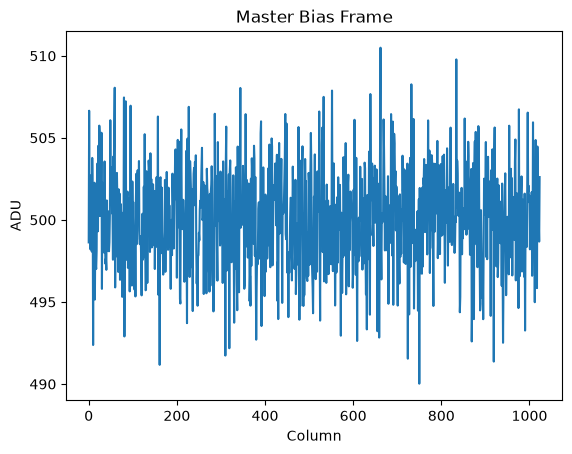

In [99]:
# average master bias down the columns and plot
plt.figure()
plt.plot(np.mean(master_bias_frame, axis=0))
plt.xlabel('Column')
plt.ylabel('ADU')
plt.title('Master Bias Frame')
plt.show()

In [100]:
# measure read noise from difference of two bias frames sigma(B_1 - B_2)/sqrt(2)

def read_noise(bias_a, bias_b, robust=False):
    """Read noise in ADU rms, from two bias frames."""
    if robust:
        return sigma_read
    else:
        return np.std(bias_a.astype(float) - bias_b.astype(float)) / np.sqrt(2)

# compare read noise from two bias frames vs. standard deviation of single bias frame
read_noise_1 = read_noise(bias_frames[0], bias_frames[1])
read_noise_2 = read_noise(bias_frames[2], bias_frames[3])
std_dev_1 = np.std(bias_frames[0])
std_dev_2 = np.std(bias_frames[1])
print(f"Read noise (frames 1 & 2): {read_noise_1:.2f} ADU")
print(f"Standard deviation (frame 1): {std_dev_1:.2f} ADU")
print(f"Read noise (frames 3 & 4): {read_noise_2:.2f} ADU")
print(f"Standard deviation (frame 2): {std_dev_2:.2f} ADU")


Read noise (frames 1 & 2): 3.97 ADU
Standard deviation (frame 1): 4.97 ADU
Read noise (frames 3 & 4): 3.97 ADU
Standard deviation (frame 2): 4.97 ADU


### 1.2 Written

*Explain which of the two numbers is the read noise and what the other one is measuring.*

The read noise is the standard deviation of the difference of two bias frames (normalized by a factor of $\frac{1}{\sqrt 2}$). This doesn't agree with the standard deviation from a single frame precisely because, as stated in 1.1, ``each column of a CMOS sensor is digitized by its own analog-to-digital converter, and they do not agree with one another perfectly." The standard deviation, meanwhile, measures read noise as well as fixed spatial bias structure --- in particular, this is an artifact of the column-to-column ADC offsets that we saw in the first plot above.

### 1.3

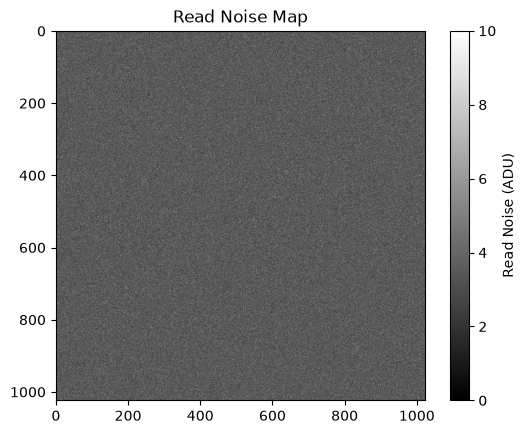

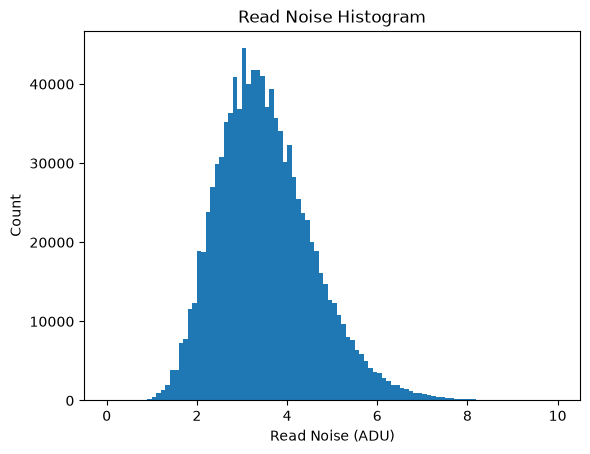

Read noise map median: 3.41 ADU
Read noise map RMS: 3.77 ADU


In [101]:
# Building a read noise map by taking the std of the ten-frame stack pixel by pixel. Plotting map itself and histogram
read_noise_map = np.std(bias_frames, axis=0)
plt.figure()
plt.imshow(read_noise_map, cmap='gray', vmin=0, vmax=10)
plt.colorbar(label='Read Noise (ADU)')
plt.title('Read Noise Map')
plt.show()

plt.figure()
plt.hist(read_noise_map.ravel(), bins=100, range=(0, 10))
plt.xlabel('Read Noise (ADU)')
plt.ylabel('Count')
plt.title('Read Noise Histogram')
plt.show()

# reporting median and RMS of the map
print(f"Read noise map median: {np.median(read_noise_map):.2f} ADU")
print(f"Read noise map RMS: {np.sqrt(np.mean(read_noise_map**2)):.2f} ADU")

### 1.3 written

The datasheet explicity quotes the median of the per-pixel RMS read-noise distribution rather than the median pixel itself. This makes sense as what the data sheet quotes is closer to the median RMS we obtained than the literal median we obtained.

### 1.4 written

Recall that aperture variance will end up being the sum of the variances of each pixel:
$$\sigma_{\textrm{aperture}}^2 = \sum_{i} \sigma_i^2,$$
so a single representative value will satisfy $R^2 = E[\sigma_i^2]$, hence the RMS is a much more natural choice than the median (which is probably one of the reasons why the datasheet reports the RMS value of the median pixel).

# Section 2 — Linearity and Full Well


### 2.1 Gain from a middle pair


In [102]:
# Use the central 512 x 512 pixels, away from the edges.
central_box = np.s_[256:768, 256:768]
bias_level = np.mean(master_bias_frame[central_box])
read_noise_median = np.median(read_noise_map)
read_noise_rms = np.sqrt(np.mean(read_noise_map**2))

# Pair 8 is in the middle of the ladder and safely below the knee.
# Convert unsigned FITS arrays to float before adding or subtracting them.
lamp_pairs = []
exposure_times = []
for i in range(1, 15):
    paths = [calib_path / 'illuminated' / f'lamp_{i:02d}{member}.fits'
             for member in ('a', 'b')]
    lamp_pairs.append(tuple(fits.getdata(path).astype(float)[central_box]
                            for path in paths))
    times = [fits.getheader(path)['EXPTIME'] for path in paths]
    assert times[0] == times[1], 'Pair exposure times must match.'
    exposure_times.append(times[0])
exposure_times = np.array(exposure_times)

# function to actually measure gan

def measure_gain(pair, bias_level, read_noise):
    """Gain in e-/ADU from the bias-subtracted mean and pair variance."""
    frame_a, frame_b = (np.asarray(frame, dtype=float) for frame in pair)
    signal = (np.mean(frame_a) + np.mean(frame_b)) / 2 - bias_level
    variance = np.var(frame_a - frame_b, ddof=1) / 2
    return signal / (variance - read_noise**2)

# doing some of the calculations and printing results

gain = measure_gain(lamp_pairs[7], bias_level, read_noise_rms)
gain_without_read_noise = measure_gain(lamp_pairs[7], bias_level, 0)
gain_correction_percent = 100 * (gain / gain_without_read_noise - 1)
print(f'Gain (pair 8): {gain:.4f} e-/ADU')
print(f'Data sheet: 1.20 e-/ADU; difference: {100 * (gain / 1.20 - 1):+.3f}%')
print(f'Without read-noise correction: {gain_without_read_noise:.4f} e-/ADU')
print(f'Read-noise correction increases gain by {gain_correction_percent:.3f}%')


Gain (pair 8): 1.1999 e-/ADU
Data sheet: 1.20 e-/ADU; difference: -0.009%
Without read-noise correction: 1.1981 e-/ADU
Read-noise correction increases gain by 0.146%


### 2.1 Discussion

The measured gain is **1.1999 e⁻/ADU**, essentially equal to the 1.20 e⁻/ADU stated in the data sheet. Subtracting the read-noise variance changes it by only **0.146%**. Pair 8 has enough signal for shot noise to dominate, while remaining below the nonlinear region. A much fainter pair would make the read-noise subtraction more influential; a pair near saturation would suppress the difference variance and give a misleading gain.

The RMS of the Section 1 temporal noise map is used here because its square represents the mean read-noise variance. The median describes a typical pixel instead. Section 1 used the population standard deviation of ten samples, which slightly underestimates the temporal variance; its effect on this bright-pair gain is small.


### 2.2 Bias and read noise in electrons


In [103]:
# Convert bias level and read noise to electrons

bias_electrons = bias_level * gain
read_noise_median_electrons = read_noise_median * gain
read_noise_rms_electrons = read_noise_rms * gain
print(f'Central bias level: {bias_level:.2f} ADU = {bias_electrons:.2f} e- equivalent')
print(f'Median temporal read noise: {read_noise_median:.2f} ADU = {read_noise_median_electrons:.2f} e- rms')
print(f'RMS of temporal noise map: {read_noise_rms:.2f} ADU = {read_noise_rms_electrons:.2f} e- rms')
print('Data sheet: 4.50 e- rms for the median pixel; no nominal bias level supplied.')


Central bias level: 499.98 ADU = 599.92 e- equivalent
Median temporal read noise: 3.41 ADU = 4.09 e- rms
RMS of temporal noise map: 3.77 ADU = 4.52 e- rms
Data sheet: 4.50 e- rms for the median pixel; no nominal bias level supplied.


### 2.2 Discussion

The bias is approximately **600 e⁻ equivalent**, the median temporal read noise is **4.09 e⁻ rms**, and the RMS of the map is **4.52 e⁻ rms**. The data sheet specifies **4.50 e⁻ rms for the median pixel**, so the matching comparison is the median, about 9% lower. The ten-frame population standard deviation is biased low; multiplying by $\sqrt{10/9}$ would raise the median to about 4.32 e⁻. Sampling scatter and variation among pixels also matter.

The RMS map value happens to be close to the data-sheet number, but it measures a different statistic. The bias is an electronic offset expressed in equivalent electrons, not accumulated photoelectrons; the data sheet provides no bias specification to compare with it.


### 2.3 Signal versus exposure time and departure from linearity


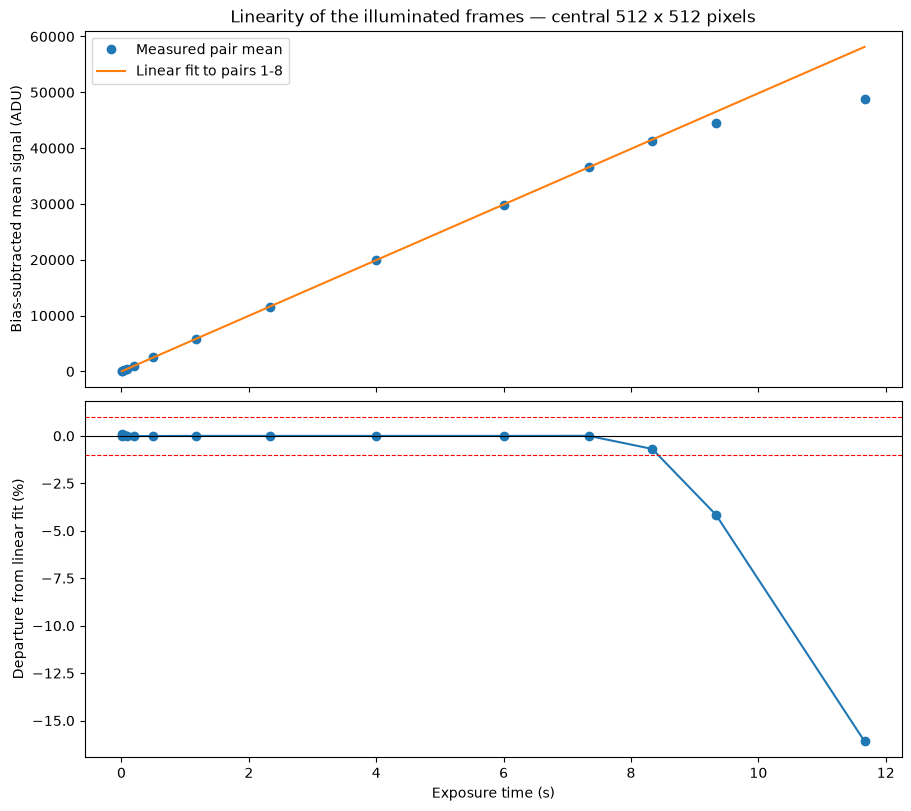

Linear fit: signal = 4983.24 ADU/s * time + 0.037 ADU
Pair   Time (s)    Signal (ADU)    Departure (%)
 1       0.0050          24.96        +0.011
 2       0.0150          74.86        +0.098
 3       0.0333         166.08        +0.059
 4       0.0833         415.18        +0.011
 5       0.2000         996.58        -0.011
 6       0.5000        2491.50        -0.006
 7       1.1667        5813.99        +0.000
 8       2.3333       11627.46        +0.000
 9       4.0000       19932.94        -0.000
10       6.0000       29899.62        +0.000
11       7.3333       36544.51        +0.002
12       8.3333       41241.94        -0.686
13       9.3333       44578.27        -4.154
14      11.6667       48784.09       -16.089


In [104]:
mean_signals = np.array([(np.mean(a) + np.mean(b)) / 2 - bias_level
                         for a, b in lamp_pairs])

# Fit only pairs 1-8 (up to 2.3333 s), i.e. below the knee.

low_signal = np.arange(len(lamp_pairs)) < 8
linear_slope, linear_intercept = np.polyfit(
    exposure_times[low_signal], mean_signals[low_signal], 1)
linear_prediction = linear_slope * exposure_times + linear_intercept
departure_percent = 100 * (mean_signals - linear_prediction) / linear_prediction


fig, axes = plt.subplots(2, 1, figsize=(9, 8), sharex=True, layout='constrained')
axes[0].plot(exposure_times, mean_signals, 'o', label='Measured pair mean')
axes[0].plot(exposure_times, linear_prediction, '-', label='Linear fit to pairs 1-8')
axes[0].set_ylabel('Bias-subtracted mean signal (ADU)')
axes[0].set_title('Linearity of the illuminated frames — central 512 x 512 pixels')
axes[0].legend()
axes[1].plot(exposure_times, departure_percent, 'o-')
axes[1].axhline(0, color='black', linewidth=0.8)
for limit in (-1, 1):
    axes[1].axhline(limit, color='red', linestyle='--', linewidth=0.8)
axes[1].set_xlabel('Exposure time (s)')
axes[1].set_ylabel('Departure from linear fit (%)')
plt.show()

print(f'Linear fit: signal = {linear_slope:.2f} ADU/s * time + {linear_intercept:.3f} ADU')
print('Pair   Time (s)    Signal (ADU)    Departure (%)')
for i, (time, signal, departure) in enumerate(
        zip(exposure_times, mean_signals, departure_percent), start=1):
    print(f'{i:2d}     {time:8.4f}     {signal:10.2f}      {departure:+8.3f}')


### 2.3 Discussion

The low-signal fit has a slope of **4983.24 ADU/s** and an intercept near zero after bias subtraction. Pairs 1–11 closely follow this line. Pair 12 is about **0.686% below** it, pair 13 is **4.154% below**, and pair 14 is **16.089% below**. The downward departure shows the detector saturating as the well fills.


### 2.4 Linearity limit, full well, and an observing rule


In [105]:
# the desired quantities

first_nonlinear = np.flatnonzero(np.abs(departure_percent) > 1)[0]
last_linear = first_nonlinear - 1
knee_signal = mean_signals[first_nonlinear]
safe_raw_level = mean_signals[last_linear] + bias_level
brightest_signal = mean_signals[-1]

# printing these quantities

print(f'First sampled departure >1%: pair {first_nonlinear + 1}, '
      f'{departure_percent[first_nonlinear]:+.3f}%')
print(f'At that pair: {knee_signal:.2f} ADU above bias = {knee_signal * gain:.2f} e-')
print(f'Raw level at that pair: {knee_signal + bias_level:.2f} ADU')
print(f'Last sampled point within 1%: {mean_signals[last_linear]:.2f} ADU above bias')
print(f'Conservative peak-pixel ceiling: below {safe_raw_level:.0f} raw ADU')
print(f'Brightest measured mean: {brightest_signal:.2f} ADU above bias = '
      f'{brightest_signal * gain:.2f} e-')
print('Full well is not directly reached: brightest mean is a lower bound, not a plateau.')
print('Data-sheet full well: 62000 e-.')


First sampled departure >1%: pair 13, -4.154%
At that pair: 44578.27 ADU above bias = 53488.95 e-
Raw level at that pair: 45078.25 ADU
Last sampled point within 1%: 41241.94 ADU above bias
Conservative peak-pixel ceiling: below 41742 raw ADU
Brightest measured mean: 48784.09 ADU above bias = 58535.46 e-
Full well is not directly reached: brightest mean is a lower bound, not a plateau.
Data-sheet full well: 62000 e-.


### 2.4 Discussion

The first sampled point exceeding 1% departure is pair 13, at **44,578 ADU above bias**, or **53,489 e⁻** (about **45,078 raw ADU**). The actual crossing lies between pairs 12 and 13; the sampling does not determine it precisely. At the telescope, keep the **peak pixel below approximately 41,700 raw ADU**, with additional margin in practice. This is the last sampled mean level verified to be within 1%; the rule concerns the peak pixel of the source, not its mean or total flux.

The brightest pair reaches **58,535 e⁻ per pixel in the central mean**, indicating a full-well scale of roughly $6\times10^4$ e⁻, consistent with the nominal **62,000 e⁻**. However, the curve is still rising, suggesting these frames may not establish a saturation plateau. Thus, 62,000 e⁻ remains a data-sheet value rather than an independently confirmed measurement --- though its quite close to what we obtained and therefore should be taken as reasonable without more information. 


### 2.5 ADC saturation versus well filling


In [106]:
adc_limit = 65535
adc_signal_electrons = (adc_limit - bias_level) * gain
nominal_full_well = 62000
nominal_full_well_raw = nominal_full_well / gain + bias_level
print(f'ADC limit: {adc_limit} raw ADU = {adc_signal_electrons:.0f} e- above bias')
print(f'Nominal full-well equivalent: {nominal_full_well_raw:.0f} raw ADU')
print(f'Brightest observed raw pixel: {max(np.max(frame) for pair in lamp_pairs for frame in pair):.0f} ADU')


ADC limit: 65535 raw ADU = 78035 e- above bias
Nominal full-well equivalent: 52171 raw ADU
Brightest observed raw pixel: 49907 ADU


### 2.5 Discussion

The ADC limit corresponds to approximately **78,035 e⁻ above bias**, greater than the nominal **62,000 e⁻** well capacity (about **52,171 raw ADU** at this gain). The well therefore fills before the ADC reaches 65,535 ADU. The observed response bends well below the ADC ceiling, so detector nonlinearity is the practical restriction for precision photometry even before full well.

Lowering the camera's electronic gain generally increases $g$ in e⁻/ADU: each electron produces fewer ADU. If the physical well capacity remains unchanged, the ADC can then represent still more electrons, so the well remains the limiting factor. A setting that changes the readout mode or effective well capacity would require a new calibration.


### 2.6 Pair-difference variance versus single-frame variance


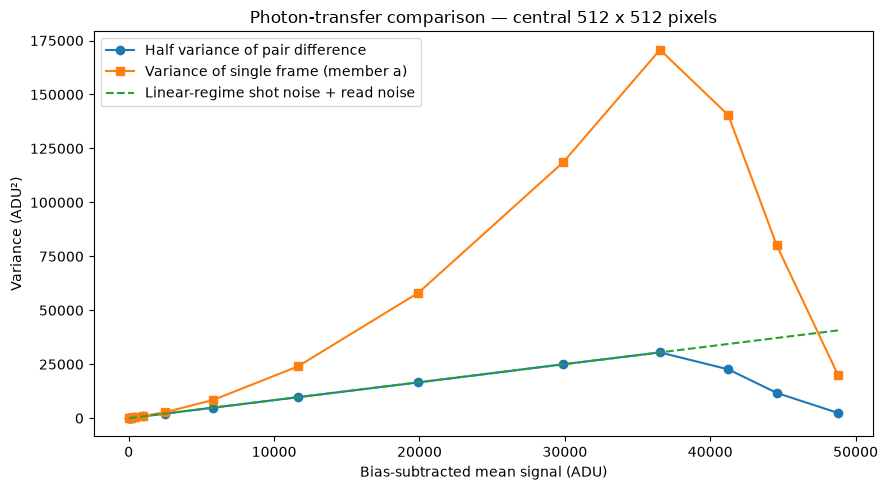

In [107]:
pair_variances = np.array([np.var(a - b, ddof=1) / 2 for a, b in lamp_pairs])
single_variances = np.array([np.var(a, ddof=1) for a, b in lamp_pairs])
plt.figure(figsize=(9, 5))
plt.plot(mean_signals, pair_variances, 'o-', label='Half variance of pair difference')
plt.plot(mean_signals, single_variances, 's-', label='Variance of single frame (member a)')
plt.plot(mean_signals, mean_signals / gain + read_noise_rms**2,
         '--', label='Linear-regime shot noise + read noise')
plt.xlabel('Bias-subtracted mean signal (ADU)')
plt.ylabel('Variance (ADU²)')
plt.title('Photon-transfer comparison — central 512 x 512 pixels')
plt.legend()
plt.tight_layout()
plt.show()


### 2.6 Discussion

In the linear regime, half the pair-difference variance rises approximately as $S/g + \sigma_{\rm read}^2$. Differencing cancels the common spatial response pattern, leaving temporal noise. The single-frame variance also contains fixed spatial structure, including pixel-to-pixel sensitivity variation, which grows approximately as signal squared. This explains its increasing excess over the pair-difference variance and why a flat-field correction can remove that structure.

Near the knee, the pair-difference variance turns down because the nonlinear response compresses fluctuations. Those points should not be used to measure the gain. At low signal, fixed bias structure can also contribute to the single-frame variance, so the entire gap is not exclusively sensitivity variation.


# Section 3

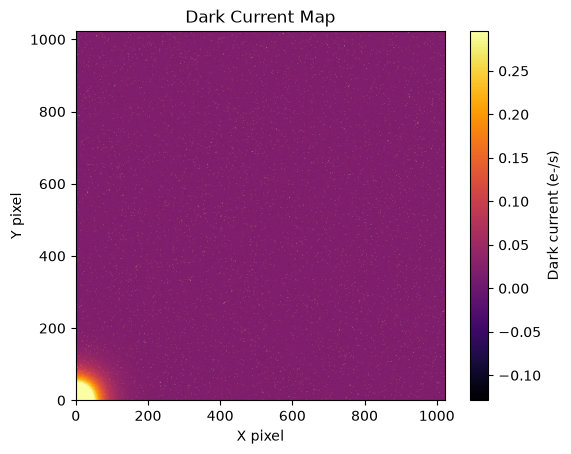

In [108]:
# subtract master bias from the two 600 s darks, average these two,
# divide by the exposure time, and multiply by the gain
dark_paths = sorted((calib_path / 'dark').glob('dark_*.fits'))
dark_exposure_times = np.array([fits.getheader(path)['EXPTIME'] for path in dark_paths])
long_dark_frames = [fits.getdata(path).astype(float)
                    for path, time in zip(dark_paths, dark_exposure_times) if time == 600]
dark_current = np.mean(long_dark_frames, axis=0) - master_bias_frame
dark_current /= 600  # exposure time
dark_current *= gain

min_current, max_current, mean_current, median_current = np.min(dark_current), np.max(dark_current), np.mean(dark_current), np.median(dark_current)

# plot the dark-rate map in e-/s

plot_clipping = np.percentile(dark_current, 99.5)

plt.imshow(dark_current, cmap='inferno', origin='lower', vmin=min_current, vmax=plot_clipping)
plt.colorbar(label='Dark current (e-/s)')
plt.title('Dark Current Map')
plt.xlabel('X pixel')
plt.ylabel('Y pixel')
plt.show()



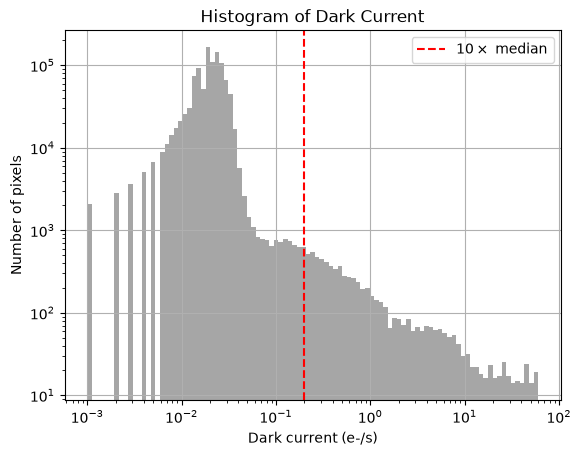

In [109]:
# histogram of the dark-rate map on log scale for x, y axes

positive_dark_current = dark_current[dark_current > 0]

bins = np.logspace(
    np.log10(np.min(positive_dark_current)),
    np.log10(np.max(positive_dark_current)),
    100
)

plt.figure()
plt.hist(positive_dark_current, bins=bins, log=True,
         color='gray', alpha=0.7)

plt.xscale('log')
plt.axvline(10 * median_current, color='red', linestyle='--',
            label=r'$10\times$ median')

plt.xlabel('Dark current (e-/s)')
plt.ylabel('Number of pixels')
plt.title('Histogram of Dark Current')
plt.legend()
plt.grid()
plt.show()


In [110]:
# bad pixel mask of all pixels above 10* median rate in the dark current map
bad_pixel_mask = dark_current > 10 * median_current

# apply the bad pixel mask to the dark frames
dark_frames_masked = [np.where(bad_pixel_mask, np.nan, frame) for frame in dark_frames]

### Subsection 3.3

In [111]:
# for each frame in dark:
# subtract master bias, take sigma-clipped mean over unmasked pixels
# then fit that signal against exposure time
def sigma_clipped_mean(data):
    """Mean after up to five rounds of 3-sigma clipping about the median."""
    data = np.asarray(data, dtype=float)
    data = data[np.isfinite(data)]
    for _ in range(5):
        keep = np.abs(data - np.median(data)) <= 3 * np.std(data)
        if np.all(keep):
            break
        data = data[keep]
    return np.mean(data)

dark_current_signals = []
for frame in dark_frames_masked:
    frame = frame - master_bias_frame
    dark_current_signals.append(sigma_clipped_mean(frame))

# fit bias-subtracted ADU against seconds, then convert the slope to e-/s
dark_current_slope, dark_current_intercept = np.polyfit(
    dark_exposure_times, dark_current_signals, 1)
dark_current_slope *= gain
print(f"Dark current from exposure-time fit: {dark_current_slope:.5f} e-/s/pixel")
print(f"Fit intercept: {dark_current_intercept:.3f} ADU")

# Determine and report uncertainty in the dark-current slope
dark_current_slope_uncertainty = gain * np.sqrt(np.diag(np.polyfit(
    dark_exposure_times, dark_current_signals, 1, cov=True)[1]))[0]
print(f"Uncertainty in dark current slope: {dark_current_slope_uncertainty:.5f} e-/s/pixel")

Dark current from exposure-time fit: 0.01985 e-/s/pixel
Fit intercept: 0.133 ADU
Uncertainty in dark current slope: 0.00024 e-/s/pixel


In [112]:
# determining whether the intercept is consistent with zero
fit, cov = np.polyfit(dark_exposure_times, dark_current_signals, 1, cov=True)
slope_adu, intercept = fit
sigma_slope_adu, sigma_intercept = np.sqrt(np.diag(cov))

D = slope_adu * gain
sigma_D = sigma_slope_adu * gain

print(f"Dark current: {D:.5f} +/- {sigma_D:.5f} e-/s/pixel")
print(f"Intercept: {intercept:.3f} +/- {sigma_intercept:.3f} ADU")

Dark current: 0.01985 +/- 0.00024 e-/s/pixel
Intercept: 0.133 +/- 0.061 ADU


The intercept is small but marginally inconsistent with zero at roughly $2.2\sigma$, suggesting a small residual systematic or imperfect clipping/masking.

In [113]:
# do the same thing as above for each frame in dark_temp
# and fit D(T) = D(T_0)*2^((T-T_0)/T_d)
dark_temp_paths = sorted((calib_path / 'dark_temp').glob('dark_*.fits'))
dark_temperatures = np.array([fits.getheader(path)['CCD-TEMP'] for path in dark_temp_paths])
dark_temp_exposure_times = np.array([fits.getheader(path)['EXPTIME'] for path in dark_temp_paths])
dark_temp_signals = []
for frame, time in zip(dark_temp_frames, dark_temp_exposure_times):
    frame = frame.astype(float) - master_bias_frame
    dark_temp_signals.append(sigma_clipped_mean(frame[~bad_pixel_mask]) / time * gain)

# log2(D) is linear in temperature; use T_0 = -10 C
dark_temp_slope, dark_temp_intercept = np.polyfit(
    dark_temperatures + 10, np.log2(dark_temp_signals), 1)
dark_doubling_temperature = 1 / dark_temp_slope
dark_rate_at_minus10 = 2**dark_temp_intercept
print(f"Temperature-fit dark current at -10 C: {dark_rate_at_minus10:.5f} e-/s/pixel")
print(f"Dark-current doubling interval: {dark_doubling_temperature:.2f} C")


Temperature-fit dark current at -10 C: 0.02052 e-/s/pixel
Dark-current doubling interval: 6.40 C


### 3.4 Discussion

The fitted doubling temperature is $T_d = 6.4$ degrees celsius. As suggested in the problem statement, this value is expected to be slightly too large because some amp glow likely survives our mask. Since amp glow is not thermal and is approximately independent of temperature, it contributes a relatively larger pedestal when the true dark current is small, flattening the measured temperature dependence and therefore biasing the fitted doubling temperature upward.

In [114]:
# find the three number

# dark rate of typical (median) pixel
median_dark_current = np.median(dark_current[~bad_pixel_mask])

# mean rate over the whole detector, including hot pixels and glow
mean_dark_current = np.mean(dark_current)

# mean with masked pixels
mean_dark_current_masked = np.mean(dark_current[~bad_pixel_mask])

# fraction of pixels we masked
fraction_masked = np.sum(bad_pixel_mask) / dark_current.size


# print results coherently
print(f"Median dark current: {median_dark_current} e-/s")
print(f"Mean dark current (all pixels): {mean_dark_current} e-/s")
print(f"Mean dark current (masked pixels): {mean_dark_current_masked} e-/s")
print(f"Fraction of masked pixels: {fraction_masked}")


Median dark current: 0.01999814036396935 e-/s
Mean dark current (all pixels): 0.035569209798267096 e-/s
Mean dark current (masked pixels): 0.020988161019211606 e-/s
Fraction of masked pixels: 0.006710052490234375


# Section 4 — The Noise Budget


### 4.1 Per-pixel uncertainty and hand check


In [115]:
def pixel_sigma(data, bias, gain, read_noise):
    """Raw-frame uncertainty in electrons; data/bias in ADU, read_noise in e- rms."""
    signal_electrons = gain * (np.asarray(data, dtype=float) - np.asarray(bias, dtype=float))
    # The bias-subtracted raw signal already includes sky, source, and dark charge.
    # Clamp negative estimates of the expected Poisson signal to zero.
    return np.sqrt(np.maximum(signal_electrons, 0) + read_noise**2)

signal_variance = 1.2 * (700 - 500)
read_variance = 4.8**2
sigma = pixel_sigma(700, 500, 1.2, 4.8)
print(f'Signal term: {signal_variance:.2f} e-²')
print(f'Read-noise term: {read_variance:.2f} e-²')
print(f'sqrt(240 + 23.04) = {sigma:.4f} e- rms (16.2 e- rounded)')
assert np.isclose(sigma, np.sqrt(263.04))

# I also did all of the above on a calculator and agreed with the results.


Signal term: 240.00 e-²
Read-noise term: 23.04 e-²
sqrt(240 + 23.04) = 16.2185 e- rms (16.2 e- rounded)


### 4.2 Check against a star-free region of NEO_001


Exposure: 120.0 s; sensor temperature: -10.0 °C
Sky-box mean: 693.71 raw ADU
Bias-subtracted mean: 193.82 ADU = 232.56 e-
Predicted standard deviation: 15.91 e- rms
Measured standard deviation: 16.58 e- rms
Measured vs. predicted departure: +4.22%


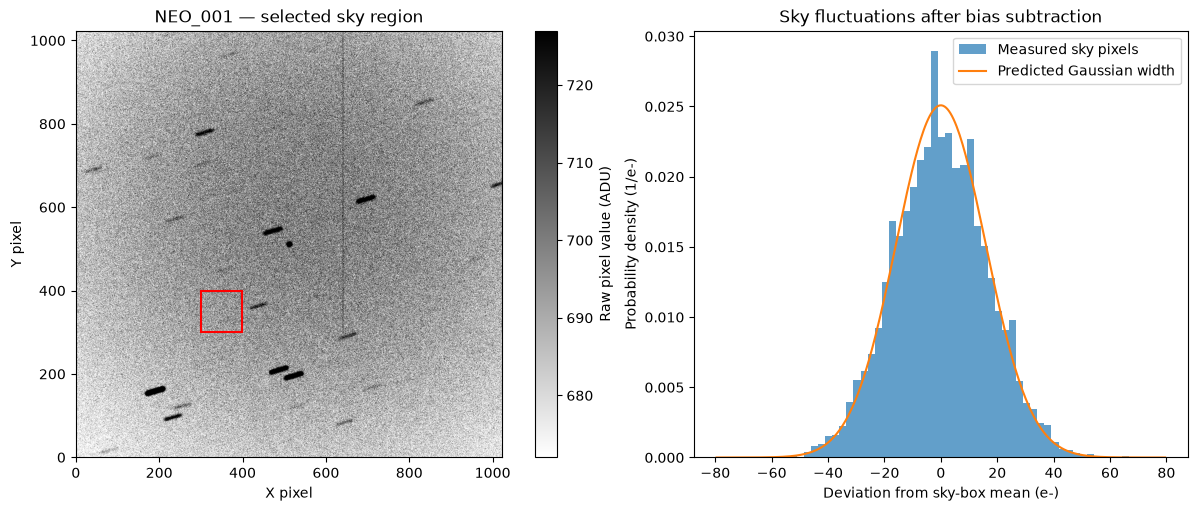

In [116]:
from matplotlib.patches import Rectangle

neo_path = calib_path.resolve().parent.parent / 'pset2' / 'data' / 'NEO_001.fits'
neo_data = fits.getdata(neo_path).astype(float)
neo_header = fits.getheader(neo_path)
neo_exposure = float(neo_header['EXPTIME'])

# Visually checked box: x = 300:400, y = 300:400 (zero-based pixels).
sky_box = np.s_[300:400, 300:400]

# getting the necessary data from the box and computing values
sky_pixels = neo_data[sky_box]
sky_bias = master_bias_frame[sky_box]
noise_R = read_noise_rms * gain  # Section 1 map RMS converted to electrons
sky_mean_raw = np.mean(sky_pixels)
sky_signal_electrons = np.mean((sky_pixels - sky_bias) * gain)
predicted_sky_sigma = np.sqrt(np.mean(pixel_sigma(sky_pixels, sky_bias, gain, noise_R)**2))
measured_sky_sigma = np.std((sky_pixels - sky_bias) * gain, ddof=1)
noise_difference_percent = 100 * (measured_sky_sigma / predicted_sky_sigma - 1)

# printing key data
print(f'Exposure: {neo_exposure:.1f} s; sensor temperature: {neo_header["CCD-TEMP"]:.1f} °C')
print(f'Sky-box mean: {sky_mean_raw:.2f} raw ADU')
print(f'Bias-subtracted mean: {sky_signal_electrons / gain:.2f} ADU = {sky_signal_electrons:.2f} e-')
print(f'Predicted standard deviation: {predicted_sky_sigma:.2f} e- rms')
print(f'Measured standard deviation: {measured_sky_sigma:.2f} e- rms')
print(f'Measured vs. predicted departure: {noise_difference_percent:+.2f}%')


# plotting
fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout='constrained')
vmin, vmax = np.percentile(neo_data, [10, 99])
image = axes[0].imshow(neo_data, origin='lower', cmap='gray_r', vmin=vmin, vmax=vmax)
axes[0].add_patch(Rectangle((299.5, 299.5), 100, 100, fill=False, edgecolor='red', linewidth=1.5))
axes[0].set_title('NEO_001 — selected sky region')
axes[0].set_xlabel('X pixel')
axes[0].set_ylabel('Y pixel')
fig.colorbar(image, ax=axes[0], label='Raw pixel value (ADU)')
residual_electrons = (sky_pixels - sky_bias) * gain - sky_signal_electrons
axes[1].hist(residual_electrons.ravel(), bins=50, density=True, alpha=0.7, label='Measured sky pixels')
x = np.linspace(-5 * predicted_sky_sigma, 5 * predicted_sky_sigma, 300)
axes[1].plot(x, np.exp(-0.5 * (x / predicted_sky_sigma)**2) /
             (np.sqrt(2 * np.pi) * predicted_sky_sigma), label='Predicted Gaussian width')
axes[1].set_title('Sky fluctuations after bias subtraction')
axes[1].set_xlabel('Deviation from sky-box mean (e-)')
axes[1].set_ylabel('Probability density (1/e-)')
axes[1].legend()
plt.show()


### 4.2 Discussion

The measured vs. predicted departure do agree to within a few percent, indicating that our constants are correct or close to correct.

### 4.3 Individual variance terms and sky/read crossover


In [117]:
# Obtain the dark-rate input directly
# from the calibration files, using their actual exposure times.
dark_paths = sorted((calib_path / 'dark').glob('dark_*.fits'))
dark_times = np.array([fits.getheader(path)['EXPTIME'] for path in dark_paths], dtype=float)
long_dark_frames = [fits.getdata(path).astype(float)
                    for path, time in zip(dark_paths, dark_times) if time == 600]
dark_rate_for_mask = (np.mean(long_dark_frames, axis=0) - master_bias_frame) * gain / 600
noise_bad_pixels = dark_rate_for_mask > 10 * np.median(dark_rate_for_mask)
dark_mean_electrons = np.array([
    np.mean((fits.getdata(path).astype(float) - master_bias_frame)[~noise_bad_pixels]) * gain
    for path in dark_paths])
noise_dark_rate_m10, noise_dark_intercept = np.polyfit(dark_times, dark_mean_electrons, 1)

# In this star-free box, source charge is zero. Remove the estimated dark
# charge to separate the sky and dark terms; do not count dark charge twice.
sky_charge = sky_signal_electrons - noise_dark_rate_m10 * neo_exposure
sky_rate = sky_charge / neo_exposure
sky_variance = sky_charge
dark_variance = noise_dark_rate_m10 * neo_exposure
read_variance = noise_R**2
sky_read_crossover = read_variance / sky_rate
print(f'Masked mean dark-rate fit at -10 °C: {noise_dark_rate_m10:.5f} e-/s/pixel')
print(f'Dark fit intercept: {noise_dark_intercept:.3f} e-/pixel')
print(f'Sky rate: {sky_rate:.4f} e-/s/pixel')
print(f'At {neo_exposure:.0f} s:')
for label, variance in [('Sky/source shot noise', sky_variance),
                        ('Dark shot noise', dark_variance), ('Read noise', read_variance)]:
    print(f'  {label}: variance = {variance:.3f} e-²; rms = {np.sqrt(variance):.3f} e-')
print(f'Quadrature total: {np.sqrt(sky_variance + dark_variance + read_variance):.3f} e- rms')
print(f'Sky-shot/read-noise equality at t = {sky_read_crossover:.2f} s')

Masked mean dark-rate fit at -10 °C: 0.02076 e-/s/pixel
Dark fit intercept: 0.141 e-/pixel
Sky rate: 1.9173 e-/s/pixel
At 120 s:
  Sky/source shot noise: variance = 230.070 e-²; rms = 15.168 e-
  Dark shot noise: variance = 2.492 e-²; rms = 1.579 e-
  Read noise: variance = 20.425 e-²; rms = 4.519 e-
Quadrature total: 15.906 e- rms
Sky-shot/read-noise equality at t = 10.65 s


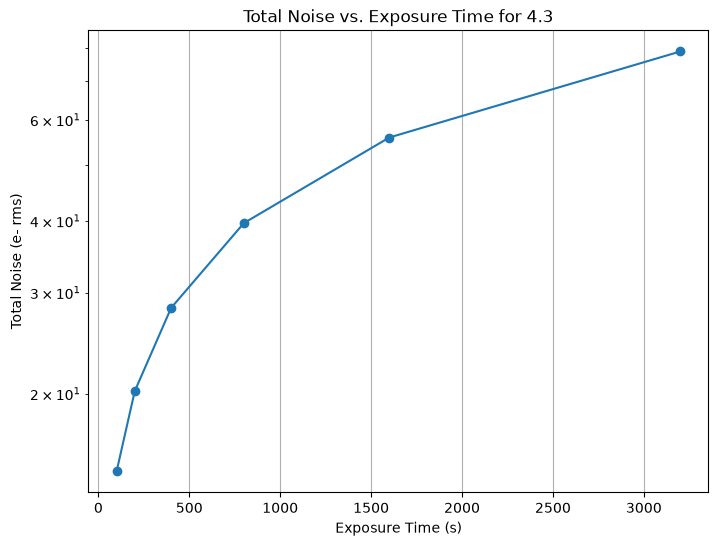

In [118]:
# graph of noise versus exposure time for 4.3

noise_exposure_times = np.array([100, 200, 400, 800, 1600, 3200])
total_noise = np.sqrt((sky_rate + noise_dark_rate_m10) * noise_exposure_times + read_variance)

plt.figure(figsize=(8, 6))
plt.plot(noise_exposure_times, total_noise, marker='o')
plt.yscale('log')
plt.xlabel('Exposure Time (s)')
plt.ylabel('Total Noise (e- rms)')
plt.title('Total Noise vs. Exposure Time for 4.3')
plt.grid()
plt.show()


### 4.3 Discussion

The NEO exposure time was relatively short (specifically, 120 seconds), so the main source of error was sky/source shot noise rather than read noise or another type of noise that scales with exposure time. 


### 4.4 Dark/read crossovers at -10 °C and +5 °C


In [119]:
# Fit Eq. (3) in log space: D(T) = D(-10) * 2**((T + 10) / T_d).

# Use the same hot-pixel mask and mean statistic at every temperature.
noise_temp_paths = sorted((calib_path / 'dark_temp').glob('dark_*.fits'))
noise_temperatures = np.array([fits.getheader(path)['CCD-TEMP'] for path in noise_temp_paths])
noise_temp_rates = np.array([
    np.mean((fits.getdata(path).astype(float) - master_bias_frame)[~noise_bad_pixels])
    * gain / fits.getheader(path)['EXPTIME'] for path in noise_temp_paths])
assert np.all(noise_temp_rates > 0), 'Log-space temperature fit requires positive rates.'
temp_slope, temp_intercept = np.polyfit(noise_temperatures, np.log2(noise_temp_rates), 1)
noise_doubling_temperature = 1 / temp_slope
noise_temp_reference_rate = 2**(temp_intercept - 10 * temp_slope)

# Note we get a slightly different value of T_d because we are using a different statistic
# than in Problem 3.4.

# Anchor the extrapolation at the -10 °C exposure-time fit from 4.3.
noise_dark_rate_p5 = noise_dark_rate_m10 * 2**(15 / noise_doubling_temperature)
dark_read_crossover_m10 = read_variance / noise_dark_rate_m10
dark_read_crossover_p5 = read_variance / noise_dark_rate_p5
print(f'Temperature-fit doubling interval: {noise_doubling_temperature:.2f} °C')
print(f'Temperature-fit D(-10 °C): {noise_temp_reference_rate:.5f} e-/s/pixel')
print(f'Exposure-time-fit D(-10 °C), used as anchor: {noise_dark_rate_m10:.5f} e-/s/pixel')
for temperature, rate, crossover in [(-10, noise_dark_rate_m10, dark_read_crossover_m10),
                                      (5, noise_dark_rate_p5, dark_read_crossover_p5)]:
    print(f'At {temperature:+d} °C: D = {rate:.5f} e-/s/pixel; '
          f'D*t = R² at {crossover:.1f} s ({crossover / 60:.2f} min)')

# Optional project-specific calculation: replace None with your planned exposure in seconds.
project_exposure_seconds = None
if project_exposure_seconds is not None:
    print(f'Project exposure: {project_exposure_seconds:.1f} s')
    print(f'Sky variance: {sky_rate * project_exposure_seconds:.2f} e-² (assuming this sky level)')
    print(f'Read variance: {read_variance:.2f} e-²')
    print(f'Dark variance at -10 °C: {noise_dark_rate_m10 * project_exposure_seconds:.2f} e-²')
    print(f'Dark variance at +5 °C: {noise_dark_rate_p5 * project_exposure_seconds:.2f} e-²')


Temperature-fit doubling interval: 6.70 °C
Temperature-fit D(-10 °C): 0.02223 e-/s/pixel
Exposure-time-fit D(-10 °C), used as anchor: 0.02076 e-/s/pixel
At -10 °C: D = 0.02076 e-/s/pixel; D*t = R² at 983.7 s (16.39 min)
At +5 °C: D = 0.09809 e-/s/pixel; D*t = R² at 208.2 s (3.47 min)


### 4.4 Discussion

In my project, the goal is to able to determine color (Sloan r-g universally and i-r for a subset of my six target galaxies) up to 2-3 $R_e$, where $R_e$ is the radius containing half of a given galaxy's luminosity. The exposure times vary between galaxies and are highly dependent on whether my calibration is correct (since we are integrating faint signals across rather large elliptical annuli), but they generally range between 15 minutes and 2 hours per filter. 

Therefore, let us consider a calculation for the **irreducible** noise from both the dark charge and from the sky. Note that we have the following data for e$^-$ accumulation per second:

1. $D_{dark, -10}$: $0.02076$ e$^-$/s/pixel. 
2. $D_{dark, +5}$: $0.09809$ e$^-$/s/pixel.
3. $D_{sky}$: $1.917$ e$^-$/s/pixel.

The irreducible errors are the square root of what we accumulate in (a worst case scenario) 2 hours, or $7200$ seconds:

1. $\sigma_{dark, -10} = \sqrt{0.02076(7200)} \approx 12.23$ e$^-$.
2. $\sigma_{dark, +5} = \sqrt{0.09809(7200)} \approx 26.58$ e$^-$.
3. $\sigma_{sky} = \sqrt{1.917(7200)} \approx 117.48$ e$^-$.

Note that errors add in quadrature, so the actual total noise from the sky and dark current at each temperature is

1. At $-10^\circ$ Celsius:
   $$\sigma_{tot,-10} = \sqrt{12.23^2 + 117.48^2} \approx 118.12\text{ e}^-.$$

2. At $+5^\circ$ Celsius:
   $$\sigma_{tot,+5} = \sqrt{26.58^2 + 117.48^2} \approx 120.45\text{ e}^-.$$

Hence, sky shot noise remains overwhelmingly dominant: even in the worst-case 2 hour exposure, cooling from $+5^\circ$ Celsius to $-10^\circ$ Celsius only reduces the total sky-plus-dark noise from about $120.45$ e$^-$ to $118.12$ e$^-$, or by about $1.9\%$. Therefore, there is relatively little benefit to spending substantial time each night cooling the telescope all the way down to $-10^\circ$ Celsius for these observations.

# AI Use Statement

I used AI in this problem set for the following tasks:

1. Help with importing frames from files.
2. Formatting of markdown text (bolding, writing e- properly, converting my shorthand like 2^16-1 to 65,535, fixing my latex). AI was not used to actually write any discussion text or to make any claims.
3. Help with plotting libraries.
4. Writing coherent and efficient print statements
5. Determining if particular functions existed in numpy or astropy or matplotlib libraries, and quickly referencing the documentation of these functions.
